# Phase 0 spike: zero-shot Timestral on NEM prices

Backtest window: **1–31 Oct 2026**, all 5 regions. Results are produced by `uv run python -m nemcast.phase0` (see `docs/phase0_results.md`).
This notebook scores them and plots examples.

- **DA-30**: issued 12:45 NEM time on day D, scored on the next trading day
  (D+1 04:30 → D+2 04:00, 48 steps).
- **ID-5**: issued every 3 h, 5-min resolution, 12 h horizon (144 steps).
- DA-30 modes: `uni` (each region alone), `multi` (5 regions as one multivariate series),
  `uni_pd` (+ AEMO PD price as a known covariate), `uni_pd_rm` (+ PD price and PD reserve margin).
- Baselines: AEMO pre-dispatch (PD), AEMO P5MIN (first hour only), seasonal naive, persistence.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from nemcast.phase0 import score

R = Path("../data/results")
pd.set_option("display.precision", 1)

## CPU latency (2 vCPU VM)

In [ ]:
bench = pd.DataFrame(json.loads((R / "bench.json").read_text()))
bench.pivot_table(index=["case", "symmetric"], columns="model", values="seconds")

model                                         123M  209M  28M       5M
case                               symmetric                          
DA-30 multi (1x5, ctx 32768, h 79) False       9.0  13.0  2.9  6.0e-01
                                   True       26.5  26.3  6.3  1.3e+00
DA-30 uni (5x1, ctx 32768, h 79)   False      18.8  13.2  3.1  5.2e-01
                                   True       26.5  28.1  6.2  1.3e+00
ID-5 uni (5x1, ctx 32768, h 144)   False       8.4  13.8  2.9  6.2e-01
                                   True       21.8  26.4  5.1  1.2e+00
ID-5 uni (5x1, ctx 8640, h 144)    False       1.8   4.7  1.4  9.0e-02
                                   True        3.5  10.8  4.0  1.9e-01

## DA-30: all models and modes, all regions

28M ran on all 31 days; 209M on every 2nd day to save CPU, so the second table compares on those days only.

In [ ]:
da = pd.concat([pd.read_parquet(p) for p in sorted(R.glob("da30_*.parquet"))], ignore_index=True)
pts = ["aemo_pd", "naive_day", "naive_week"]
score(da[da["model"] == "28M"], pts, ["model", "mode"])

n  timestral_pinball  timestral_cover80  \
model mode                                                     
28M   multi       7440               14.7                0.8   
      uni         7440               15.0                0.8   
      uni_pd      7440               61.5                0.9   
      uni_pd_rm   7440               41.5                0.9   
      uni_pdc     7440               15.3                0.9   
      uni_pdc_rm  7440               14.5                0.9   

                  timestral_p50_mae  timestral_p50_medae  timestral_p50_rmse  \
model mode                                                                     
28M   multi                    40.6                 26.0               178.6   
      uni                      41.2                 25.4               179.0   
      uni_pd                   64.6                 19.3               467.2   
      uni_pd_rm                53.4                 18.6               321.6   
      uni_pdc                  35.8                 18.3               179.5   
      uni_pdc_rm               34.9                 18.7               176.5   

                  aemo_pd_mae  aemo_pd_medae  aemo_pd_rmse  naive_day_mae  \
model mode                                                                  
28M   multi             330.8           30.1        2224.6           55.2   
      uni               330.8           30.1        2224.6           55.2   
      uni_pd            330.8           30.1        2224.6           55.2   
      uni_pd_rm         330.8           30.1        2224.6           55.2   
      uni_pdc           330.8           30.1        2224.6           55.2   
      uni_pdc_rm        330.8           30.1        2224.6           55.2   

                  naive_day_medae  naive_day_rmse  naive_week_mae  \
model mode                                                          
28M   multi                  32.1           249.3            62.3   
      uni                    32.1           249.3            62.3   
      uni_pd                 32.1           249.3            62.3   
      uni_pd_rm              32.1           249.3            62.3   
      uni_pdc                32.1           249.3            62.3   
      uni_pdc_rm             32.1           249.3            62.3   

                  naive_week_medae  naive_week_rmse  
model mode                                           
28M   multi                   39.6            251.5  
      uni                     39.6            251.5  
      uni_pd                  39.6            251.5  
      uni_pd_rm               39.6            251.5  
      uni_pdc                 39.6            251.5  
      uni_pdc_rm              39.6            251.5

In [ ]:
common = set(da.loc[da["model"] == "209M", "issue"])
score(da[da["issue"].isin(common)], pts, ["model", "mode"])

n  timestral_pinball  timestral_cover80  \
model mode                                                     
209M  uni         3840               16.0                0.8   
      uni_pdc     3840               15.1                0.8   
28M   multi       3840               15.8                0.8   
      uni         3840               16.1                0.8   
      uni_pd      3840               85.0                0.9   
      uni_pd_rm   3840               48.7                0.9   
      uni_pdc     3840               18.9                0.8   
      uni_pdc_rm  3840               17.6                0.8   

                  timestral_p50_mae  timestral_p50_medae  timestral_p50_rmse  \
model mode                                                                     
209M  uni                      42.6                 24.3               242.4   
      uni_pdc                  36.8                 19.7               239.4   
28M   multi                    42.8                 25.4               241.8   
      uni                      43.5                 24.9               242.2   
      uni_pd                   83.5                 20.6               621.3   
      uni_pd_rm                60.3                 20.3               371.1   
      uni_pdc                  42.4                 19.7               245.4   
      uni_pdc_rm               41.2                 20.3               241.5   

                  aemo_pd_mae  aemo_pd_medae  aemo_pd_rmse  naive_day_mae  \
model mode                                                                  
209M  uni               381.8           31.0        2515.7           61.9   
      uni_pdc           381.8           31.0        2515.7           61.9   
28M   multi             381.8           31.0        2515.7           61.9   
      uni               381.8           31.0        2515.7           61.9   
      uni_pd            381.8           31.0        2515.7           61.9   
      uni_pd_rm         381.8           31.0        2515.7           61.9   
      uni_pdc           381.8           31.0        2515.7           61.9   
      uni_pdc_rm        381.8           31.0        2515.7           61.9   

                  naive_day_medae  naive_day_rmse  naive_week_mae  \
model mode                                                          
209M  uni                    33.2           334.1            62.0   
      uni_pdc                33.2           334.1            62.0   
28M   multi                  33.2           334.1            62.0   
      uni                    33.2           334.1            62.0   
      uni_pd                 33.2           334.1            62.0   
      uni_pd_rm              33.2           334.1            62.0   
      uni_pdc                33.2           334.1            62.0   
      uni_pdc_rm             33.2           334.1            62.0   

                  naive_week_medae  naive_week_rmse  
model mode                                           
209M  uni                     38.8            247.3  
      uni_pdc                 38.8            247.3  
28M   multi                   38.8            247.3  
      uni                     38.8            247.3  
      uni_pd                  38.8            247.3  
      uni_pd_rm               38.8            247.3  
      uni_pdc                 38.8            247.3  
      uni_pdc_rm              38.8            247.3

### DA-30 by region (best Timestral config vs baselines)

In [ ]:
s = score(da[da["issue"].isin(common)], pts, ["model", "mode"])
best = s["timestral_pinball"].idxmin()
print("best:", best)
best_da = da[(da["model"] == best[0]) & (da["mode"] == best[1])]
score(best_da, pts, ["region"])

best: ('209M', 'uni_pdc')


,n,timestral_pinball,timestral_cover80,timestral_p50_mae,timestral_p50_medae,timestral_p50_rmse,aemo_pd_mae,aemo_pd_medae,aemo_pd_rmse,naive_day_mae,naive_day_medae,naive_day_rmse,naive_week_mae,naive_week_medae,naive_week_rmse
region,,,,,,,,,,,,,,,
NSW1,768,32.5,0.9,65.9,18.9,528.7,1185.4,31.0,4956.9,105.5,24.8,733.1,82.7,32.4,530.4
QLD1,768,9.5,0.8,24.2,16.7,34.2,452.0,25.4,2531.5,35.4,25.4,54.3,43.7,33.1,65.1
SA1,768,13.1,0.9,35.7,25.4,51.1,151.1,46.0,801.8,64.3,50.7,88.7,65.4,52.5,92.6
TAS1,768,9.9,0.8,28.3,17.2,40.8,49.5,23.5,83.5,43.5,29.9,59.5,56.1,43.1,71.9
VIC1,768,10.4,0.9,29.8,21.7,40.4,71.1,34.4,124.5,60.7,47.1,79.1,62.1,51.5,80.0


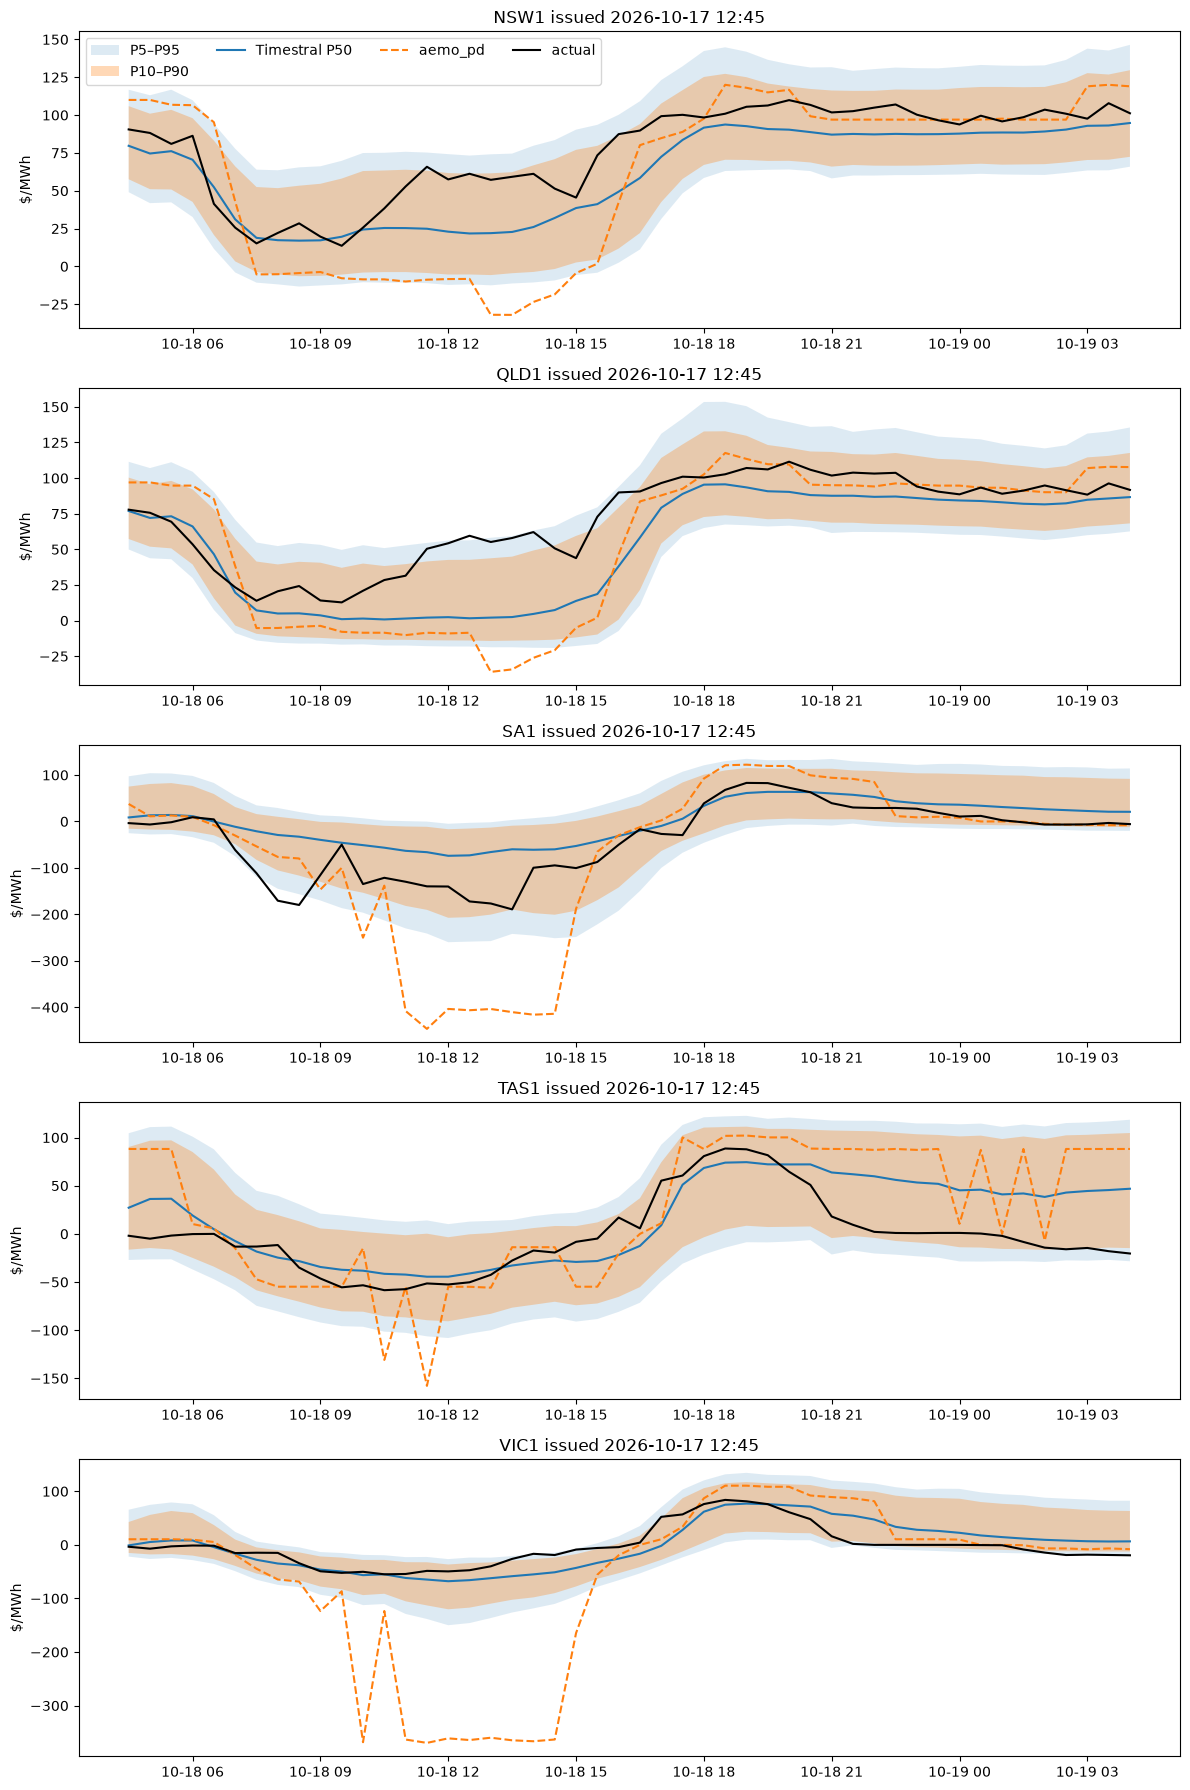

In [ ]:
def fan(df, issue, region, point_cols, ax):
    d = df[(df["issue"] == issue) & (df["region"] == region)].set_index("valid_time")
    ax.fill_between(d.index, d["q05"], d["q95"], alpha=0.15, label="P5–P95")
    ax.fill_between(d.index, d["q10"], d["q90"], alpha=0.3, label="P10–P90")
    ax.plot(d.index, d["q50"], label="Timestral P50")
    for c in point_cols:
        ax.plot(d.index, d[c], "--", label=c)
    ax.plot(d.index, d["actual"], "k", lw=1.5, label="actual")
    ax.set_title(f"{region} issued {issue:%Y-%m-%d %H:%M}")
    ax.set_ylabel("$/MWh")


issues = sorted(best_da["issue"].unique())
fig, axes = plt.subplots(5, 1, figsize=(12, 18))
for ax, r in zip(axes, ["NSW1", "QLD1", "SA1", "TAS1", "VIC1"], strict=False):
    fan(best_da, issues[len(issues) // 2], r, ["aemo_pd"], ax)
axes[0].legend(ncol=4)
fig.tight_layout()
fig.savefig("../docs/img/phase0_da30_fan.png", dpi=80)

## ID-5: by lead-time bucket

In [ ]:
ids = pd.concat([pd.read_parquet(p) for p in sorted(R.glob("id5_*.parquet"))], ignore_index=True)
ids["lead"] = pd.cut(ids["lead_min"], [0, 60, 180, 360, 720], labels=["0-1h", "1-3h", "3-6h", "6-12h"])
pts5 = ["aemo_p5min", "aemo_pd", "persistence", "naive_day"]
score(ids, pts5, ["model", "lead"])

n  timestral_pinball  timestral_cover80  timestral_p50_mae  \
model lead                                                                    
28M   0-1h   14880                5.6                0.8               15.8   
      1-3h   29760               10.3                0.8               25.9   
      3-6h   44640               12.2                0.8               32.1   
      6-12h  89280               14.2                0.8               38.6   

             timestral_p50_medae  timestral_p50_rmse  aemo_p5min_mae  \
model lead                                                             
28M   0-1h                   5.9               123.6            25.9   
      1-3h                  10.7               281.9             NaN   
      3-6h                  16.0               246.6             NaN   
      6-12h                 21.6               248.0             NaN   

             aemo_p5min_medae  aemo_p5min_rmse  aemo_pd_mae  aemo_pd_medae  \
model lead                                                                   
28M   0-1h                6.7            466.4         34.5            8.5   
      1-3h                NaN              NaN         45.6           11.7   
      3-6h                NaN              NaN         54.8           14.4   
      6-12h               NaN              NaN         67.9           17.5   

             aemo_pd_rmse  persistence_mae  persistence_medae  \
model lead                                                      
28M   0-1h          588.1             20.8                6.6   
      1-3h          685.8             40.6               12.5   
      3-6h          754.6             56.2               25.4   
      6-12h         844.4             73.9               46.0   

             persistence_rmse  naive_day_mae  naive_day_medae  naive_day_rmse  
model lead                                                                     
28M   0-1h              235.8           48.4             27.4           208.1  
      1-3h              395.9           53.7             26.6           399.7  
      3-6h              375.3           51.9             26.8           347.8  
      6-12h             378.3           51.8             26.7           347.7

In [ ]:
score(ids[ids["lead"] == "0-1h"], pts5, ["region"])

,n,timestral_pinball,timestral_cover80,timestral_p50_mae,timestral_p50_medae,timestral_p50_rmse,aemo_p5min_mae,aemo_p5min_medae,aemo_p5min_rmse,aemo_pd_mae,aemo_pd_medae,aemo_pd_rmse,persistence_mae,persistence_medae,persistence_rmse,naive_day_mae,naive_day_medae,naive_day_rmse
region,,,,,,,,,,,,,,,,,,
NSW1,2976,9.9,0.8,28.2,7.0,272.1,71.1,8.7,1041.1,99.2,9.7,1312.6,45.3,8.9,524.2,60.5,24.5,445.8
QLD1,2976,4.4,0.8,12.6,5.9,22.3,15.2,8.0,29.5,15.7,8.4,27.4,15.3,7.0,27.6,38.1,23.8,57.7
SA1,2976,6.3,0.8,17.4,6.8,33.6,18.8,7.1,42.3,26.8,10.1,62.9,19.8,7.5,39.0,54.4,36.2,79.3
TAS1,2976,3.6,0.8,10.0,4.3,18.5,12.6,4.2,25.7,15.8,6.7,28.9,11.2,4.5,21.1,38.9,22.1,57.2
VIC1,2976,4.0,0.8,11.1,5.3,20.2,11.8,5.2,24.5,15.0,7.6,28.8,12.2,5.7,23.3,50.1,34.6,70.1


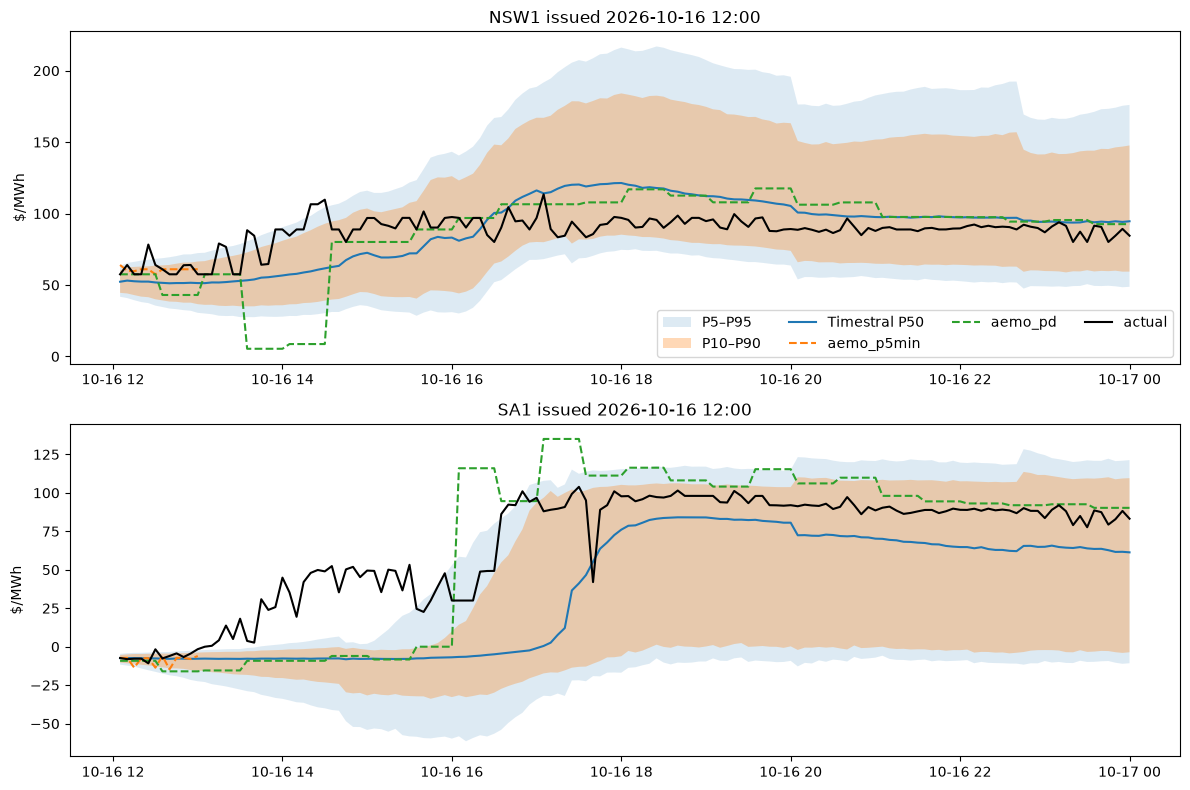

In [ ]:
iss = sorted(ids["issue"].unique())
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, r in zip(axes, ["NSW1", "SA1"], strict=False):
    fan(ids, iss[len(iss) // 2], r, ["aemo_p5min", "aemo_pd"], ax)
axes[0].legend(ncol=4)
fig.tight_layout()
fig.savefig("../docs/img/phase0_id5_fan.png", dpi=80)